# 02 — Spectral methods: kernel PCA, MDS, Isomap (Yifei)

Owner: **Yifei**. Only Yifei edits this notebook.

All three methods share one recipe: build an $n\times n$ symmetric matrix from the data, double-centre it, keep its top $q$ eigenvectors. They differ only in the matrix:

| method | matrix that is double-centred | hyperparameter |
|---|---|---|
| PCA = classical MDS | $-\tfrac12 D^{(2)}$, squared Euclidean distances (Gram matrix of $X$) | none |
| kernel PCA | kernel matrix $K_{ij}=k(x_i,x_j)$ | kernel, bandwidth $\sigma$ or degree |
| Isomap | $-\tfrac12 D_G^{(2)}$, squared graph-geodesic distances | number of neighbours $k$ |

So Isomap is kernel PCA with a data-dependent "kernel" (Ham et al. 2004), which need not be positive semidefinite.

**Questions.**
1. Do the spectral methods beat the PCA baseline on MNIST, in-sample (Track B) and out-of-sample (Track A)?
2. How do $\sigma$ (kernel PCA) and $k$ (Isomap) control the result, and can the methods overfit?
3. What do the spectra say about the geometry of MNIST (non-Euclidean geodesics, intrinsic dimension)?

**Outline.**
0. Setup
1. The three methods, with their out-of-sample maps
2. Sanity checks
3. Main run: all configurations on all 5 splits
4. Track B (in-sample): tune on $X_{\mathrm{val}}$, report on $X_{\mathrm{te}}$
5. Track A (out-of-sample): fit on $X_{\mathrm{tr}}$, tune on $X_{\mathrm{val}}$, report on $X_{\mathrm{te}}$
6. Hyperparameters and overfitting
7. The kernel PCA path from "memorising" to PCA
8. Isomap: the role of $k$, and how non-Euclidean the geodesics are
9. Intrinsic dimension: residual variance
10. Conclusions

Protocol and notation: `notes/evaluation_protocol.tex`. Outputs: `results/02_*.csv`, `figures/02_*.png|pdf`.

## 0. Setup

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))          # make nldr importable from notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from nldr import data, metrics

RESULTS, FIGURES = ROOT / "results", ROOT / "figures"
RESULTS.mkdir(exist_ok=True); FIGURES.mkdir(exist_ok=True)

def save(fig, name):
    """Save a figure as figures/<name>.png and .pdf."""
    for ext in ("png", "pdf"):
        fig.savefig(FIGURES / f"{name}.{ext}", dpi=200, bbox_inches="tight")

def plot_rnx(curves, ax, title=None):
    """R_NX(K) against log K. curves: label -> (rnx, J)."""
    for label, (rnx, J) in curves.items():
        ax.semilogx(np.arange(1, len(rnx) + 1), rnx, label=f"{label} (J = {J:.3f})")
    ax.axhline(0, color="0.6", lw=0.8)
    ax.set(xlabel="$K$ (log scale)", ylabel="$R_{NX}(K)$", title=title)
    ax.legend(fontsize=8)

In [2]:
import time
import warnings
from dataclasses import dataclass, field
from typing import Callable

from scipy.linalg import eigh, eigvalsh
from scipy.sparse.csgraph import connected_components
from scipy.spatial.distance import cdist, pdist
from sklearn.decomposition import PCA, KernelPCA
from sklearn.manifold import Isomap
from sklearn.neighbors import kneighbors_graph

Q_FIG, Q_TAB = 2, 10        # target dimension for figures / tables (as in 01_baselines)
Q_FIT = Q_TAB               # spectral embeddings are nested: fit once with q = 10, slice to q = 2
K_REPORT = (5, 10, 50)      # K for trustworthiness T(K), continuity C(K)
KNN_K = 5                   # k for k-NN accuracy
COLORS = plt.get_cmap("tab10")

X, y = data.load_mnist()
splits = data.make_splits()
baseline = pd.read_csv(RESULTS / "baseline_pca_split0.csv", index_col="q")  # from 01_baselines
print(f"{len(splits)} splits, n = {data.N_PER_SPLIT} per sample")
baseline

5 splits, n = 2000 per sample


,J,T5,C5,T10,C10,T50,C50,spearman,centroid_corr,knn_acc,silhouette,ari,nmi
q,,,,,,,,,,,,,
2,0.1614,0.7345,0.9167,0.7336,0.9046,0.7367,0.8692,0.4902,0.8514,0.411,0.0146,0.2333,0.3643
10,0.5384,0.9871,0.9952,0.9838,0.9933,0.9702,0.9846,0.8458,0.9955,0.871,0.0876,0.3098,0.4551


## 1. The three methods

Every fit returns an `Embedding(Y, transform, info)`: the training embedding $Y\in\mathbb R^{n\times q}$, a map for new points, and diagnostics. All maps reuse the **training** statistics (means, centring), never re-estimated on new points.

- **Kernel PCA.** Gaussian kernel $k(x,x')=\exp(-\|x-x'\|^2/2\sigma^2)$ with $\sigma = c\cdot\operatorname{median}_{i\neq j}\|x_i-x_j\|$, $c\in\{0.1,0.3,1,3,10\}$; or polynomial $k(x,x')=(x^\top x'/d+1)^p$, $p\in\{2,3,5\}$. New points: $y_a(x')=\sum_i\alpha^a_i\,\tilde k(x',x_i)$ (scikit-learn).
- **Classical MDS.** $B=-\tfrac12 J_nD^{(2)}J_n=V\Lambda V^\top$, $Y=V_q\Lambda_q^{1/2}$. New points by Gower's formula
$$y(x')=\tfrac12\,\Lambda_q^{-1/2}V_q^\top\big(\bar\delta-\delta_{x'}\big),\qquad (\delta_{x'})_i=\|x'-x_i\|^2,\quad \bar\delta_i=\tfrac1n\textstyle\sum_j D^{(2)}_{ij}.$$
- **Isomap.** Symmetrised $k$-NN graph, shortest-path distances $D_G$, then classical MDS on $D_G^{(2)}$. New points: geodesic distances through their $k$ nearest training points, then the same formula (scikit-learn; Bengio et al. 2004). Disconnected graphs are recorded in `info`.

PCA is included as the reference everything is compared with.

In [3]:
@dataclass
class Embedding:
    Y: np.ndarray                                   # (n, q) training embedding
    transform: Callable[[np.ndarray], np.ndarray]   # new points (m, d) -> (m, q)
    info: dict = field(default_factory=dict)


def median_distance(Z):
    """Median pairwise Euclidean distance: the scale for Gaussian bandwidths."""
    return float(np.median(pdist(Z)))


def double_centre(D2):
    """B = -1/2 J D2 J, and the row means of D2 (needed by Gower's formula)."""
    r = D2.mean(axis=1)
    return -0.5 * (D2 - r[:, None] - r[None, :] + r.mean()), r


def fit_pca(Z, q):
    m = PCA(n_components=q, svd_solver="full").fit(Z)
    return Embedding(m.transform(Z), m.transform, {"eigenvalues": m.explained_variance_})


def fit_kpca(Z, q, kernel="rbf", sigma_factor=1.0, degree=3):
    kw = dict(n_components=q, kernel=kernel, eigen_solver="dense")
    info = {"kernel": kernel}
    if kernel == "rbf":
        sigma = sigma_factor * median_distance(Z)
        kw["gamma"] = 1.0 / (2.0 * sigma ** 2)
        info["sigma"] = sigma
    elif kernel == "poly":
        kw.update(degree=degree, coef0=1.0)          # gamma = 1/d (scikit-learn default)
    m = KernelPCA(**kw).fit(Z)
    info["eigenvalues"] = m.eigenvalues_
    return Embedding(m.transform(Z), m.transform, info)


def fit_mds(Z, q):
    D2 = cdist(Z, Z, "sqeuclidean")
    B, row_mean = double_centre(D2)
    lam, V = eigh(B)
    lam, V = lam[::-1], V[:, ::-1]
    Vq, inv_sqrt = V[:, :q], 1.0 / np.sqrt(np.clip(lam[:q], 1e-12, None))
    Y = Vq * np.sqrt(np.clip(lam[:q], 0, None))

    def transform(Zn):                                # Gower's out-of-sample formula
        delta = cdist(Zn, Z, "sqeuclidean")
        return 0.5 * (row_mean[None, :] - delta) @ Vq * inv_sqrt

    return Embedding(Y, transform, {"eigenvalues": lam})


def graph_components(Z, k):
    G = kneighbors_graph(Z, k, mode="connectivity", include_self=False)
    return int(connected_components(G.maximum(G.T), directed=False)[0])


def fit_isomap(Z, q, n_neighbors=10):
    with warnings.catch_warnings():   # disconnected graphs for small k: recorded in info instead
        warnings.simplefilter("ignore")
        m = Isomap(n_neighbors=n_neighbors, n_components=q, eigen_solver="dense").fit(Z)

    def transform(Zn):
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            return m.transform(Zn)

    return Embedding(m.embedding_, transform,
                     {"graph_components": graph_components(Z, n_neighbors), "model": m})


FIT = {"pca": fit_pca, "kpca": fit_kpca, "mds": fit_mds, "isomap": fit_isomap}
GRIDS = {   # same grids as the group protocol (about 10 configurations or fewer per method)
    "pca": [{}],
    "mds": [{}],
    "kpca": [{"kernel": "rbf", "sigma_factor": c} for c in (0.1, 0.3, 1.0, 3.0, 10.0)]
            + [{"kernel": "poly", "degree": p} for p in (2, 3, 5)],
    "isomap": [{"n_neighbors": k} for k in (5, 10, 20, 50, 100)],
}
NAMES = {"pca": "PCA", "kpca": "kernel PCA", "mds": "MDS", "isomap": "Isomap"}


def config_label(params):
    if not params:
        return "-"
    if "n_neighbors" in params:
        return f"k={params['n_neighbors']}"
    if params.get("kernel") == "poly":
        return f"poly p={params['degree']}"
    return f"rbf c={params['sigma_factor']:g}"


def fit(name, Z, q=Q_FIT, params=None):
    return FIT[name](np.asarray(Z, float), q, **(params or {}))

In [4]:
# Scores. The input ranks do not depend on the method, so they are computed once per sample.

def J_in(rho, Y):
    """In-sample AUC_log(R_NX) of an embedding Y of the points whose input ranks are rho."""
    return metrics.auc_log(metrics.rnx_curve(rho, metrics.rank_matrix(Y)))


def rnx_oos(rho_cross, Y_tr, Y_new):
    """metrics.rnx_curve_oos with the input cross-ranks rank(X_new among X_tr) precomputed."""
    r = metrics._cross_ranks(Y_new, Y_tr)
    m, n = rho_cross.shape
    counts = np.bincount(np.maximum(rho_cross, r).ravel(), minlength=n + 1)[1:]
    K = np.arange(1, n + 1)
    qq = np.cumsum(counts) / (m * K)
    K, qq = K[:-1], qq[:-1]
    return (n * qq - K) / (n - K)


def J_oos(rho_cross, Y_tr, Y_new):
    return metrics.auc_log(rnx_oos(rho_cross, Y_tr, Y_new))


def cca_similarity(A, B):
    """Mean canonical correlation between two embeddings of the same points.

    1 iff the column spaces of the centred embeddings coincide, i.e. B is an invertible
    linear map of A: a similarity that ignores rotations, reflections and scalings.
    """
    qa, _ = np.linalg.qr(A - A.mean(0))
    qb, _ = np.linalg.qr(B - B.mean(0))
    return float(np.linalg.svd(qa.T @ qb, compute_uv=False).mean())

## 2. Sanity checks

1. Classical MDS on Euclidean distances is PCA (same embedding up to the sign of each axis).
2. Kernel PCA with the linear kernel is PCA.
3. Gower's formula applied to the training points returns the training embedding.
4. Kernel PCA with a very wide Gaussian ($c=100$) is close to PCA: $\tilde K\approx \tilde X\tilde X^\top/\sigma^2$ to first order.
5. The fast `rnx_oos` equals `metrics.rnx_curve_oos`.

In [5]:
s0 = splits[0]
Xs = X[s0.val[:500]]                 # small sample: checks only
Y_pca = fit_pca(Xs, Q_TAB).Y
e_mds = fit_mds(Xs, Q_TAB)
Y_lin = KernelPCA(Q_TAB, kernel="linear", eigen_solver="dense").fit_transform(Xs)
Y_wide = fit_kpca(Xs, Q_TAB, sigma_factor=100.0).Y
X_new = X[s0.te[:300]]
e_small = fit_pca(X[s0.tr[:400]], Q_TAB)

checks = {
    "MDS = PCA (up to signs)": np.allclose(np.abs(e_mds.Y), np.abs(Y_pca), atol=1e-6),
    "linear kernel PCA = PCA (up to signs)": np.allclose(np.abs(Y_lin), np.abs(Y_pca), atol=1e-6),
    "Gower map on training points = Y_MDS": np.allclose(e_mds.transform(Xs), e_mds.Y, atol=1e-6),
    "MDS map = PCA map on new points": np.allclose(np.abs(e_mds.transform(X_new)),
                                                    np.abs(fit_pca(Xs, Q_TAB).transform(X_new)), atol=1e-6),
    "rbf c=100 close to PCA (CCA > 0.99)": cca_similarity(Y_wide, Y_pca) > 0.99,
    "rnx_oos = metrics.rnx_curve_oos": np.allclose(
        rnx_oos(metrics._cross_ranks(X_new, X[s0.tr[:400]]), e_small.Y, e_small.transform(X_new)),
        metrics.rnx_curve_oos(X[s0.tr[:400]], e_small.Y, X_new, e_small.transform(X_new))),
}
for k, v in checks.items():
    print(("PASS " if v else "FAIL ") + k)
print(f"CCA similarity of rbf c=100 with PCA: {cca_similarity(Y_wide, Y_pca):.5f}")
assert all(checks.values())

PASS MDS = PCA (up to signs)
PASS linear kernel PCA = PCA (up to signs)
PASS Gower map on training points = Y_MDS
PASS MDS map = PCA map on new points
PASS rbf c=100 close to PCA (CCA > 0.99)
PASS rnx_oos = metrics.rnx_curve_oos
CCA similarity of rbf c=100 with PCA: 1.00000


## 3. Main run: every configuration on every split

For each split $s$ and each configuration we compute, with $q=2$ and $q=10$ (columns 1–2 of the $q=10$ fit, since spectral embeddings are nested):

| column | fit on | scored on | meaning |
|---|---|---|---|
| `J_B_val` | $X_{\mathrm{val}}$ | $X_{\mathrm{val}}$, in-sample | Track B selection score |
| `J_tr` | $X_{\mathrm{tr}}$ | $X_{\mathrm{tr}}$, in-sample | how well the training points are embedded |
| `J_A_val` | $X_{\mathrm{tr}}$ | $X_{\mathrm{val}}$ through the map | Track A selection score |
| `J_A_te` | $X_{\mathrm{tr}}$ | $X_{\mathrm{te}}$ through the map | Track A reported score (never used for selection) |

`J_tr − J_A_val` is the **generalisation gap** of the learned map. About 10 minutes on a laptop.

In [6]:
def run_split(sp):
    Xtr, Xval, Xte = X[sp.tr], X[sp.val], X[sp.te]
    rho_tr, rho_val = metrics.rank_matrix(Xtr), metrics.rank_matrix(Xval)
    cross_val = metrics._cross_ranks(Xval, Xtr)      # rank of each training point seen from x'
    cross_te = metrics._cross_ranks(Xte, Xtr)
    rows = []
    for name, grid in GRIDS.items():
        for params in grid:
            t0 = time.time()
            eB = fit(name, Xval, params=params)                       # Track B tuning fit
            eA = fit(name, Xtr, params=params)                        # Track A fit
            Yv, Yt = eA.transform(Xval), eA.transform(Xte)
            for q in (Q_FIG, Q_TAB):
                rows.append({
                    "split": sp.seed, "method": name, "config": config_label(params), "q": q,
                    "J_B_val": J_in(rho_val, eB.Y[:, :q]),
                    "J_tr": J_in(rho_tr, eA.Y[:, :q]),
                    "J_A_val": J_oos(cross_val, eA.Y[:, :q], Yv[:, :q]),
                    "J_A_te": J_oos(cross_te, eA.Y[:, :q], Yt[:, :q]),
                    "graph_components": eA.info.get("graph_components", np.nan),
                    "seconds": time.time() - t0,
                })
    return rows

t_start, rows = time.time(), []
for sp in splits:
    rows += run_split(sp)
    print(f"split {sp.seed} done, {time.time() - t_start:.0f} s")
runs = pd.DataFrame(rows)
runs.round(4).to_csv(RESULTS / "02_all_configs.csv", index=False)
PARAMS = {(name, config_label(p)): p for name, grid in GRIDS.items() for p in grid}
runs.head()

split 0 done, 96 s
split 1 done, 192 s
split 2 done, 294 s
split 3 done, 398 s
split 4 done, 498 s


,split,method,config,q,J_B_val,J_tr,J_A_val,J_A_te,graph_components,seconds
0,0,pca,-,2,0.163518,0.161464,0.164598,0.163398,NaN,1.817248
1,0,pca,-,10,0.533577,0.543430,0.540379,0.539010,NaN,2.891099
2,0,mds,-,2,0.163518,0.161464,0.164598,0.163398,NaN,6.447237
3,0,mds,-,10,0.533577,0.543430,0.540379,0.539010,NaN,7.513941
4,0,kpca,rbf c=0.1,2,0.018856,0.021579,-0.030970,-0.031980,NaN,3.455625


## 4. Track B — in-sample, all methods

Select the configuration with the largest `J_B_val` (fit and scored on $X_{\mathrm{val}}$), then fit on the **independent** sample $X_{\mathrm{te}}$ with it and report every criterion of `metrics.evaluate` there. Mean ± s.d. over the 5 splits.

In [7]:
def mean_sd(df, by, cols):
    g = df.groupby(by, sort=False)[cols]
    m, s = g.mean(), g.std()
    out = m.round(3).astype(str) + " ± " + s.round(3).astype(str)
    return out


selB = runs.loc[runs.groupby(["split", "method", "q"])["J_B_val"].idxmax()]
rowsB, curvesB, embB = [], {}, {}
for sp in splits:
    Xte, yte = X[sp.te], y[sp.te]
    rho_te = metrics.rank_matrix(Xte)
    for name in GRIDS:
        for q in (Q_FIG, Q_TAB):
            cfg = selB.query("split == @sp.seed and method == @name and q == @q")["config"].item()
            Y = fit(name, Xte, q=q, params=PARAMS[(name, cfg)]).Y
            res = metrics.evaluate(Xte, Y, yte, Ks=K_REPORT, rho=rho_te)
            rnx = res.pop("rnx")
            if sp.seed == 0:
                curvesB[(name, q)] = (rnx, res["J"], cfg)
                embB[(name, q)] = Y
            rowsB.append({"split": sp.seed, "method": name, "q": q, "config": cfg, **res})
trackB = pd.DataFrame(rowsB)
trackB.round(4).to_csv(RESULTS / "02_trackB.csv", index=False)

cols = ["J", "T10", "C10", "spearman", "knn_acc", "nmi"]
summaryB = mean_sd(trackB, ["q", "method"], cols)
summaryB["selected"] = trackB.groupby(["q", "method"], sort=False)["config"].agg(lambda c: ", ".join(c))
summaryB.to_csv(RESULTS / "02_trackB_summary.csv")
summaryB

,,J,T10,C10,spearman,knn_acc,nmi,selected
q,method,,,,,,,
2,pca,0.16 ± 0.002,0.734 ± 0.006,0.906 ± 0.001,0.492 ± 0.017,0.412 ± 0.02,0.357 ± 0.01,"-, -, -, -, -"
10,pca,0.538 ± 0.001,0.984 ± 0.001,0.993 ± 0.0,0.851 ± 0.007,0.862 ± 0.007,0.464 ± 0.009,"-, -, -, -, -"
2,mds,0.16 ± 0.002,0.734 ± 0.006,0.906 ± 0.001,0.492 ± 0.017,0.412 ± 0.02,0.357 ± 0.01,"-, -, -, -, -"
10,mds,0.538 ± 0.001,0.984 ± 0.001,0.993 ± 0.0,0.851 ± 0.007,0.862 ± 0.007,0.464 ± 0.009,"-, -, -, -, -"
2,kpca,0.16 ± 0.002,0.732 ± 0.004,0.904 ± 0.002,0.51 ± 0.027,0.406 ± 0.031,0.35 ± 0.024,"poly p=2, poly p=5, poly p=2, poly p=3, poly p=3"
10,kpca,0.538 ± 0.001,0.984 ± 0.001,0.993 ± 0.0,0.852 ± 0.011,0.861 ± 0.006,0.464 ± 0.009,"rbf c=10, poly p=3, rbf c=10, rbf c=10, rbf c=10"
2,isomap,0.185 ± 0.007,0.769 ± 0.012,0.936 ± 0.006,0.551 ± 0.017,0.469 ± 0.047,0.387 ± 0.032,"k=20, k=5, k=5, k=10, k=5"
10,isomap,0.569 ± 0.004,0.988 ± 0.001,0.993 ± 0.0,0.885 ± 0.003,0.864 ± 0.008,0.478 ± 0.006,"k=100, k=100, k=100, k=100, k=100"


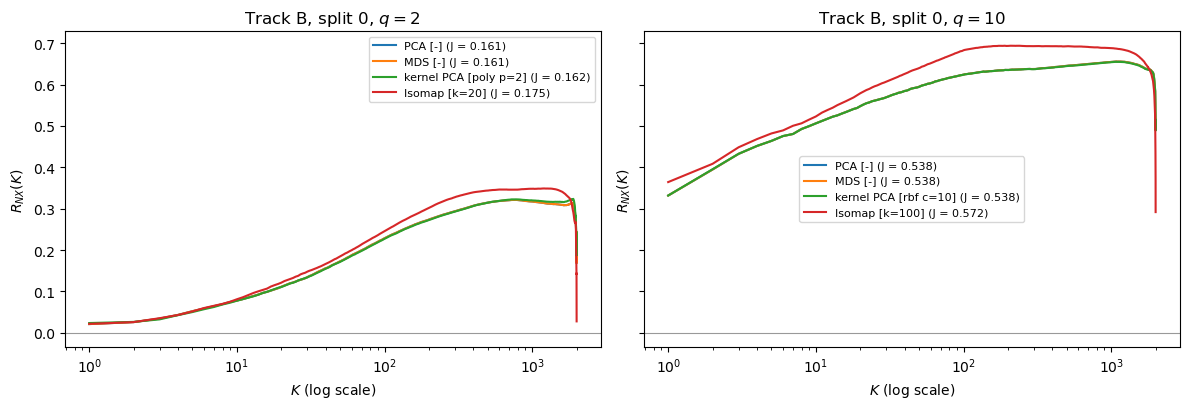

split-0 PCA here vs 01_baselines (must agree): 0.1614 0.1614 | 0.5384 0.5384


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, q in zip(axes, (Q_FIG, Q_TAB)):
    plot_rnx({f"{NAMES[n]} [{curvesB[(n, q)][2]}]": curvesB[(n, q)][:2] for n in GRIDS},
             ax, title=f"Track B, split 0, $q = {q}$")
fig.tight_layout(); save(fig, "02_rnx_trackB"); plt.show()

print("split-0 PCA here vs 01_baselines (must agree):",
      round(curvesB[('pca', 2)][1], 4), baseline.loc[2, "J"], "|",
      round(curvesB[('pca', 10)][1], 4), baseline.loc[10, "J"])

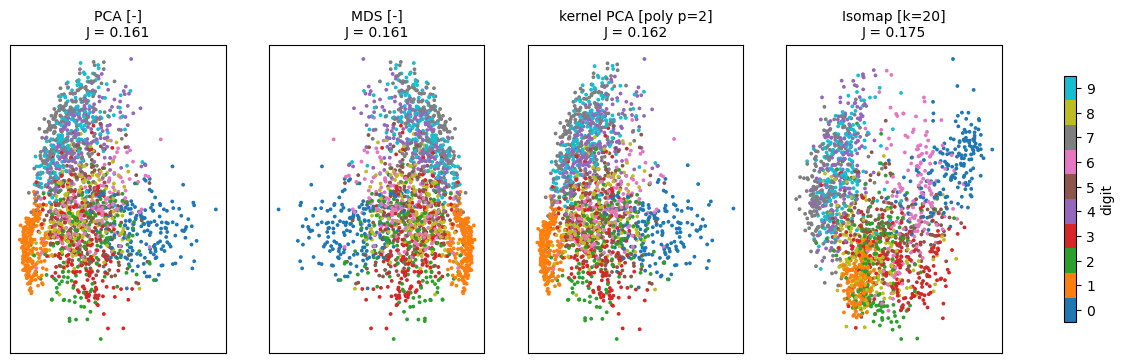

In [9]:
yte0 = y[splits[0].te]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, name in zip(axes, GRIDS):
    Y = embB[(name, Q_FIG)]
    sc = ax.scatter(Y[:, 0], Y[:, 1], c=yte0, cmap="tab10", s=3, vmin=-0.5, vmax=9.5)
    ax.set_title(f"{NAMES[name]} [{curvesB[(name, Q_FIG)][2]}]\n"
                 f"J = {curvesB[(name, Q_FIG)][1]:.3f}", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(sc, ax=axes, ticks=range(10), label="digit", shrink=0.8)
save(fig, "02_embeddings_q2"); plt.show()

## 5. Track A — out-of-sample

Fit on $X_{\mathrm{tr}}$; select the configuration with the largest `J_A_val` (validation points mapped by the learned map, training points as reference); report on $X_{\mathrm{te}}$: $\mathcal J^{\mathrm{oos}}$ and the out-of-sample $k$-NN accuracy (classifier trained on the training embedding).

In [10]:
selA = runs.loc[runs.groupby(["split", "method", "q"])["J_A_val"].idxmax()]
rowsA, curvesA = [], {}
for sp in splits:
    Xtr, Xte = X[sp.tr], X[sp.te]
    cross_te = metrics._cross_ranks(Xte, Xtr)
    for name in GRIDS:
        cfgs = selA.query("split == @sp.seed and method == @name").set_index("q")["config"]
        for q in (Q_FIG, Q_TAB):
            e = fit(name, Xtr, q=q, params=PARAMS[(name, cfgs[q])])
            Yt = e.transform(Xte)
            rnx = rnx_oos(cross_te, e.Y, Yt)
            if sp.seed == 0:
                curvesA[(name, q)] = (rnx, metrics.auc_log(rnx), cfgs[q])
            rowsA.append({"split": sp.seed, "method": name, "q": q, "config": cfgs[q],
                          "J_oos": metrics.auc_log(rnx),
                          "J_tr": J_in(metrics.rank_matrix(Xtr), e.Y),
                          "knn_acc_oos": metrics.knn_accuracy_oos(e.Y, y[sp.tr], Yt, y[sp.te], k=KNN_K)})
trackA = pd.DataFrame(rowsA)
trackA["gap"] = trackA["J_tr"] - trackA["J_oos"]
trackA.round(4).to_csv(RESULTS / "02_trackA.csv", index=False)

summaryA = mean_sd(trackA, ["q", "method"], ["J_oos", "J_tr", "gap", "knn_acc_oos"])
summaryA["selected"] = trackA.groupby(["q", "method"], sort=False)["config"].agg(lambda c: ", ".join(c))
summaryA.to_csv(RESULTS / "02_trackA_summary.csv")
summaryA

,,J_oos,J_tr,gap,knn_acc_oos,selected
q,method,,,,,
2,pca,0.16 ± 0.005,0.16 ± 0.004,0.0 ± 0.007,0.414 ± 0.008,"-, -, -, -, -"
10,pca,0.537 ± 0.005,0.54 ± 0.006,0.003 ± 0.002,0.862 ± 0.006,"-, -, -, -, -"
2,mds,0.16 ± 0.005,0.16 ± 0.004,0.0 ± 0.007,0.414 ± 0.008,"-, -, -, -, -"
10,mds,0.537 ± 0.005,0.54 ± 0.006,0.003 ± 0.002,0.862 ± 0.006,"-, -, -, -, -"
2,kpca,0.16 ± 0.006,0.16 ± 0.004,0.001 ± 0.007,0.411 ± 0.012,"rbf c=10, poly p=2, poly p=5, poly p=5, rbf c=10"
10,kpca,0.537 ± 0.005,0.54 ± 0.006,0.003 ± 0.002,0.862 ± 0.006,"rbf c=10, rbf c=10, rbf c=10, rbf c=10, rbf c=10"
2,isomap,0.186 ± 0.004,0.186 ± 0.006,-0.001 ± 0.004,0.484 ± 0.021,"k=10, k=10, k=10, k=10, k=5"
10,isomap,0.54 ± 0.004,0.568 ± 0.003,0.028 ± 0.005,0.846 ± 0.014,"k=100, k=100, k=100, k=100, k=100"


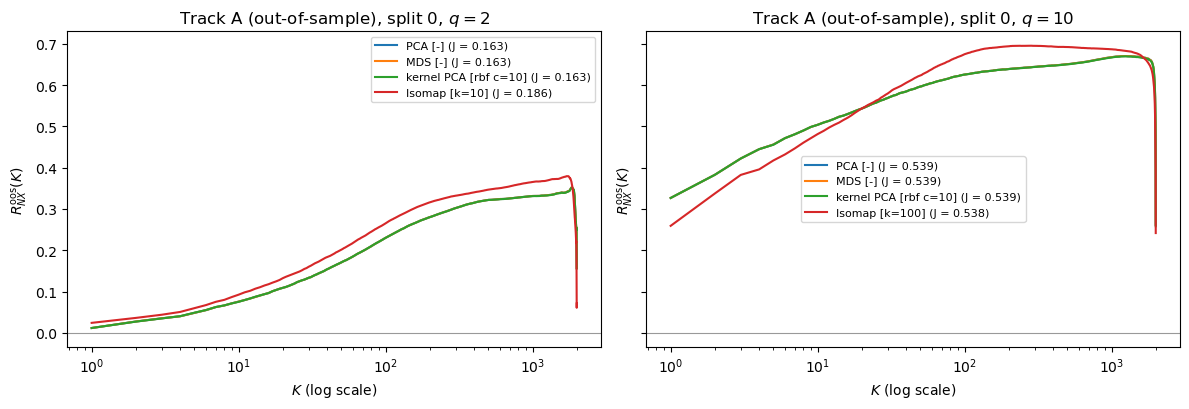

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, q in zip(axes, (Q_FIG, Q_TAB)):
    plot_rnx({f"{NAMES[n]} [{curvesA[(n, q)][2]}]": curvesA[(n, q)][:2] for n in GRIDS},
             ax, title=f"Track A (out-of-sample), split 0, $q = {q}$")
    ax.set_ylabel(r"$R^{\mathrm{oos}}_{NX}(K)$")
fig.tight_layout(); save(fig, "02_rnx_trackA"); plt.show()

## 6. Hyperparameters and overfitting

For each value on the grid: in-sample score of the training fit (`J_tr`), score of the same map on new points (`J_A_val`), and the Track B selection score (`J_B_val`). Mean ± s.d. over the 5 splits; dashed line: PCA. Where `J_tr` stays high but `J_A_val` drops, the map **memorises** the training sample.

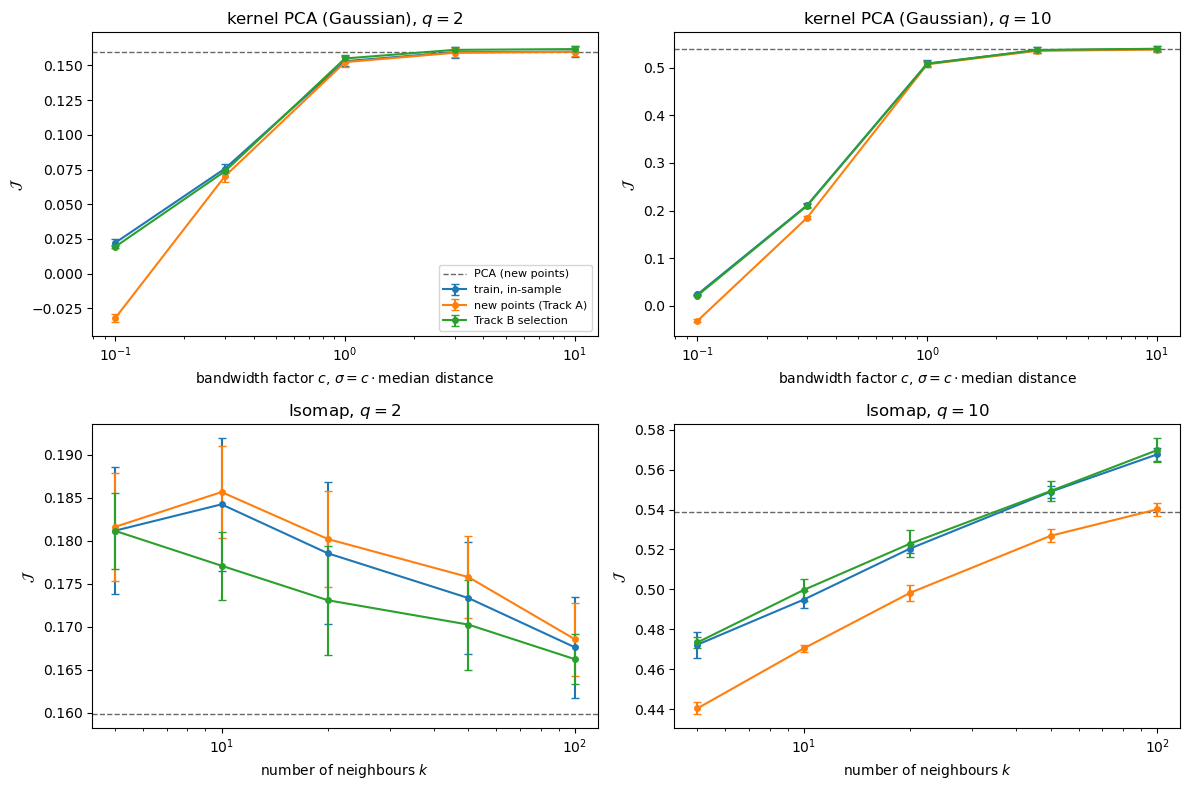

J_tr  J_A_val  J_B_val  J_A_te    gap
method config    q                                         
pca    -         10  0.540    0.539    0.540   0.537  0.001
mds    -         10  0.540    0.539    0.540   0.537  0.001
kpca   rbf c=0.1 10  0.024   -0.032    0.021  -0.032  0.056
       rbf c=0.3 10  0.211    0.185    0.210   0.185  0.026
       rbf c=1   10  0.509    0.507    0.508   0.506  0.002
       rbf c=3   10  0.537    0.536    0.537   0.534  0.001
       rbf c=10  10  0.540    0.538    0.540   0.537  0.001
       poly p=2  10  0.540    0.538    0.540   0.537  0.002
       poly p=3  10  0.539    0.537    0.540   0.536  0.002
       poly p=5  10  0.536    0.534    0.537   0.534  0.002
isomap k=5       10  0.472    0.440    0.473   0.438  0.032
       k=10      10  0.495    0.470    0.500   0.468  0.024
       k=20      10  0.520    0.498    0.523   0.498  0.022
       k=50      10  0.549    0.527    0.549   0.528  0.022
       k=100     10  0.568    0.540    0.570   0.540  0.028

In [12]:
def sweep_plot(ax, sub, x, xlabel, q, logx=True):
    sub = sub.query("q == @q")
    for col, lab, c in (("J_tr", "train, in-sample", "C0"), ("J_A_val", "new points (Track A)", "C1"),
                        ("J_B_val", "Track B selection", "C2")):
        g = sub.groupby(x)[col]
        m, s = g.mean(), g.std()
        ax.errorbar(m.index, m.values, yerr=s.values, marker="o", ms=4, capsize=3, label=lab, color=c)
    pca = runs.query("method == 'pca' and q == @q")
    ax.axhline(pca["J_A_val"].mean(), ls="--", c="0.4", lw=1, label="PCA (new points)")
    if logx:
        ax.set_xscale("log")
    ax.set(xlabel=xlabel, ylabel=r"$\mathcal{J}$", title=f"$q = {q}$")


rbf = runs[(runs.method == "kpca") & runs.config.str.startswith("rbf")].copy()
rbf["c"] = rbf["config"].str.split("=").str[1].astype(float)
iso = runs.query("method == 'isomap'").copy()
iso["k"] = iso["config"].str.split("=").str[1].astype(int)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for j, q in enumerate((Q_FIG, Q_TAB)):
    sweep_plot(axes[0, j], rbf, "c", r"bandwidth factor $c$, $\sigma = c\cdot$median distance", q)
    sweep_plot(axes[1, j], iso, "k", "number of neighbours $k$", q)
axes[0, 0].legend(fontsize=8)
for ax in axes[0]: ax.set_title("kernel PCA (Gaussian), " + ax.get_title())
for ax in axes[1]: ax.set_title("Isomap, " + ax.get_title())
fig.tight_layout(); save(fig, "02_hyperparameters"); plt.show()

hyper = runs.groupby(["method", "config", "q"], sort=False)[["J_tr", "J_A_val", "J_B_val", "J_A_te"]].mean()
hyper["gap"] = hyper["J_tr"] - hyper["J_A_val"]
hyper.round(4).to_csv(RESULTS / "02_hyperparameters.csv")
hyper.query("q == 10").round(3)

## 7. The kernel PCA path: from memorising to PCA

The Gaussian bandwidth interpolates between two limits (`evaluation_protocol.tex`, §2.2):

- $\sigma\to\infty$: $k(x,x')\approx 1-\|x-x'\|^2/2\sigma^2$, so $\tilde K\approx \tilde X\tilde X^\top/\sigma^2$ and kernel PCA $\to$ **PCA**.
- $\sigma\to 0$: $K\to I_n$ and $\tilde K\to J_n$, whose eigenvalues are all equal: no preferred direction. Each eigenvector concentrates on a few close training points, and a new point, far from all of them in kernel terms, is mapped near $0$.

On a fine grid of $c$ (split 0, $q=10$) we track four quantities:
1. $\mathcal J$ in-sample and out-of-sample (the generalisation gap);
2. similarity with PCA: mean canonical correlation between the two training embeddings ($1$ = same subspace);
3. effective dimension of the kernel spectrum, $d_{\mathrm{eff}}=(\sum_a\mu_a)^2/\sum_a\mu_a^2$ (participation ratio of the eigenvalues of $\tilde K$);
4. collapse of new points: $\operatorname{mean}\|y(x')\| / \operatorname{mean}\|y(x_i)\|$.

**Why is there no "nonlinear sweet spot" in between?** A Gaussian kernel can only be local if nearest neighbours are much closer than typical pairs. In 784 dimensions distances concentrate. The check below compares the nearest-neighbour distance with the median distance and evaluates the kernel at both.

In [13]:
Ztr = X[splits[0].tr]
Dtr = cdist(Ztr, Ztr); np.fill_diagonal(Dtr, np.inf)
nn_dist, med_all = Dtr.min(axis=1), np.median(pdist(Ztr))
print(f"median nearest-neighbour distance / median distance = {np.median(nn_dist) / med_all:.2f}"
      f"   (10% quantile: {np.quantile(nn_dist, 0.1) / med_all:.2f})")
pd.DataFrame({"c": [0.1, 0.3, 1.0, 3.0]}).assign(
    kernel_at_nearest_neighbour=lambda d: [np.median(np.exp(-nn_dist ** 2 / (2 * (c * med_all) ** 2))) for c in d.c],
    kernel_at_median_distance=lambda d: np.exp(-1 / (2 * d.c ** 2))).round(4)

median nearest-neighbour distance / median distance = 0.53   (10% quantile: 0.32)


,c,kernel_at_nearest_neighbour,kernel_at_median_distance
0,0.1,0.0000,0.0000
1,0.3,0.2067,0.0039
2,1.0,0.8677,0.6065
3,3.0,0.9844,0.9460


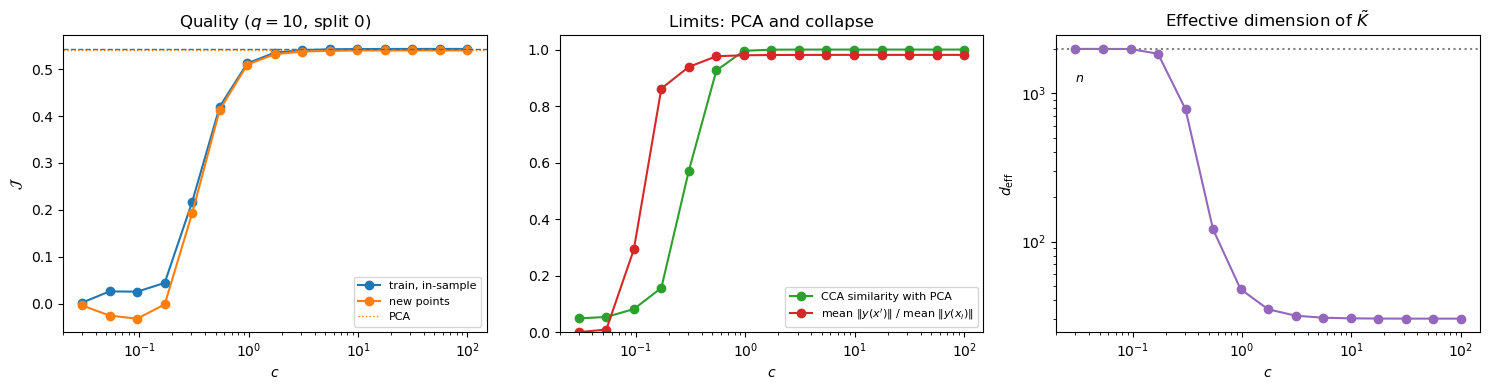

,c,J_tr,J_oos,cca_with_pca,d_eff,norm_ratio
0,0.030,0.002,-0.004,0.049,1999.000,0.000
1,0.054,0.026,-0.026,0.054,1998.991,0.009
2,0.096,0.025,-0.032,0.081,1995.780,0.292
3,0.171,0.044,-0.002,0.157,1853.702,0.862
4,0.305,0.217,0.193,0.572,780.703,0.939
5,0.544,0.420,0.413,0.926,120.733,0.976
6,0.970,0.513,0.510,0.996,47.651,0.980
7,1.732,0.535,0.532,1.000,34.852,0.981
8,3.092,0.541,0.538,1.000,31.544,0.981
9,5.519,0.543,0.539,1.000,30.568,0.981


In [14]:
sp = splits[0]
Xtr, Xval = X[sp.tr], X[sp.val]
rho_tr, cross_val = metrics.rank_matrix(Xtr), metrics._cross_ranks(Xval, Xtr)
Y_pca_tr = fit_pca(Xtr, Q_TAB).Y
med = median_distance(Xtr)
sq = cdist(Xtr, Xtr, "sqeuclidean")

rows = []
for c in np.geomspace(0.03, 100, 15):
    e = fit_kpca(Xtr, Q_TAB, sigma_factor=c)
    Yv = e.transform(Xval)
    K = np.exp(-sq / (2 * (c * med) ** 2))
    Kc = K - K.mean(0)[None, :] - K.mean(1)[:, None] + K.mean()                       # J K J
    mu = np.clip(eigvalsh(Kc), 0, None)
    rows.append({"c": c, "J_tr": J_in(rho_tr, e.Y), "J_oos": J_oos(cross_val, e.Y, Yv),
                 "cca_with_pca": cca_similarity(e.Y, Y_pca_tr),
                 "d_eff": mu.sum() ** 2 / (mu ** 2).sum(),
                 "norm_ratio": np.linalg.norm(Yv, axis=1).mean() / np.linalg.norm(e.Y, axis=1).mean()})
path = pd.DataFrame(rows)
path.round(4).to_csv(RESULTS / "02_kpca_sigma_path.csv", index=False)

J_pca_tr, J_pca_oos = J_in(rho_tr, Y_pca_tr), J_oos(cross_val, Y_pca_tr, fit_pca(Xtr, Q_TAB).transform(Xval))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ax = axes[0]
ax.semilogx(path.c, path.J_tr, "o-", label="train, in-sample")
ax.semilogx(path.c, path.J_oos, "o-", label="new points")
ax.axhline(J_pca_tr, ls="--", c="C0", lw=1); ax.axhline(J_pca_oos, ls=":", c="C1", lw=1, label="PCA")
ax.set(xlabel="$c$", ylabel=r"$\mathcal{J}$", title=r"Quality ($q=10$, split 0)"); ax.legend(fontsize=8)
ax = axes[1]
ax.semilogx(path.c, path.cca_with_pca, "o-", c="C2", label="CCA similarity with PCA")
ax.semilogx(path.c, path.norm_ratio, "o-", c="C3", label=r"mean $\|y(x')\|$ / mean $\|y(x_i)\|$")
ax.set(xlabel="$c$", ylim=(0, 1.05), title="Limits: PCA and collapse"); ax.legend(fontsize=8)
ax = axes[2]
ax.loglog(path.c, path.d_eff, "o-", c="C4")
ax.axhline(len(Xtr), ls=":", c="0.5"); ax.text(path.c.iloc[0], len(Xtr) * 0.6, "$n$", fontsize=9)
ax.set(xlabel="$c$", ylabel=r"$d_{\mathrm{eff}}$", title=r"Effective dimension of $\tilde K$")
fig.tight_layout(); save(fig, "02_kpca_sigma_path"); plt.show()
path.round(3)

## 8. Isomap: the role of $k$

Too small a $k$ disconnects the graph and the geodesics follow narrow chains; too large a $k$ creates **short circuits** across the manifold, and $D_G\to D$ (Isomap $\to$ MDS = PCA once every pair is an edge).

Non-Euclidean diagnostic: the matrix $B_G=-\tfrac12 J_nD_G^{(2)}J_n$ is positive semidefinite iff $D_G$ is a Euclidean distance matrix (Schoenberg). Its **negative mass** $\sum_{\mu_a<0}|\mu_a|\big/\sum_a|\mu_a|$ measures how far the geodesic distances are from any Euclidean configuration, i.e. how much MDS must discard. Split 0, fit on $X_{\mathrm{tr}}$.

negative mass, Swiss roll (k = 10): 0.034


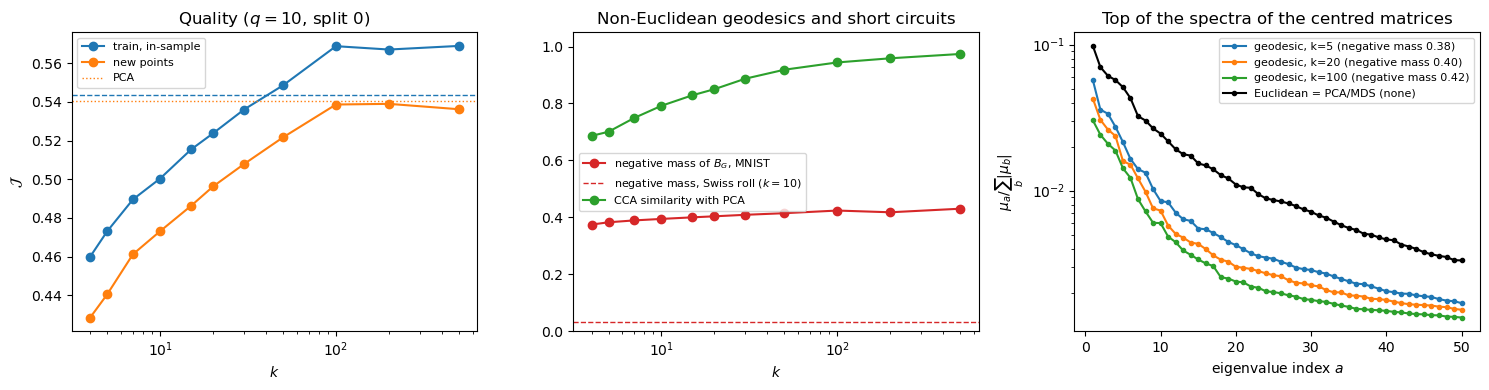

,k,graph_components,negative_mass,top10_share,J_tr,J_oos,cca_with_pca
0,4,1,0.374,0.408,0.460,0.429,0.686
1,5,1,0.382,0.385,0.473,0.441,0.701
2,7,1,0.389,0.368,0.490,0.461,0.749
3,10,1,0.394,0.350,0.500,0.473,0.792
4,15,1,0.400,0.331,0.515,0.486,0.829
5,20,1,0.403,0.320,0.524,0.496,0.850
6,30,1,0.409,0.302,0.536,0.508,0.887
7,50,1,0.414,0.282,0.549,0.522,0.919
8,100,1,0.424,0.258,0.569,0.539,0.944
9,200,1,0.418,0.245,0.567,0.539,0.959


In [15]:
rows, spectra = [], {}
for k in (4, 5, 7, 10, 15, 20, 30, 50, 100, 200, 500):
    e = fit_isomap(Xtr, Q_TAB, n_neighbors=k)
    BG, _ = double_centre(e.info["model"].dist_matrix_ ** 2)
    mu = eigvalsh(BG)[::-1]
    spectra[k] = mu
    rows.append({"k": k, "graph_components": e.info["graph_components"],
                 "negative_mass": -mu[mu < 0].sum() / np.abs(mu).sum(),
                 "top10_share": mu[:Q_TAB].sum() / mu[mu > 0].sum(),
                 "J_tr": J_in(rho_tr, e.Y), "J_oos": J_oos(cross_val, e.Y, e.transform(Xval)),
                 "cca_with_pca": cca_similarity(e.Y, Y_pca_tr)})
kpath = pd.DataFrame(rows)
kpath.round(4).to_csv(RESULTS / "02_isomap_k_path.csv", index=False)

# Reference: a genuinely flat manifold (Swiss roll, n = 2000, k = 10) has almost Euclidean geodesics.
from sklearn.datasets import make_swiss_roll
roll, _ = make_swiss_roll(len(Xtr), noise=0.0, random_state=0)
BG_roll, _ = double_centre(fit_isomap(roll, 2, n_neighbors=10).info["model"].dist_matrix_ ** 2)
mu_roll = eigvalsh(BG_roll)
neg_roll = -mu_roll[mu_roll < 0].sum() / np.abs(mu_roll).sum()
print(f"negative mass, Swiss roll (k = 10): {neg_roll:.3f}")

B_lin, _ = double_centre(sq)
mu_lin = eigvalsh(B_lin)[::-1]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ax = axes[0]
ax.semilogx(kpath.k, kpath.J_tr, "o-", label="train, in-sample")
ax.semilogx(kpath.k, kpath.J_oos, "o-", label="new points")
ax.axhline(J_pca_tr, ls="--", c="C0", lw=1); ax.axhline(J_pca_oos, ls=":", c="C1", lw=1, label="PCA")
for _, r in kpath.query("graph_components > 1").iterrows():
    ax.annotate(f"{int(r.graph_components)} comp.", (r.k, r.J_tr), fontsize=7,
                textcoords="offset points", xytext=(0, 6))
ax.set(xlabel="$k$", ylabel=r"$\mathcal{J}$", title=r"Quality ($q=10$, split 0)"); ax.legend(fontsize=8)
ax = axes[1]
ax.semilogx(kpath.k, kpath.negative_mass, "o-", c="C3", label="negative mass of $B_G$, MNIST")
ax.axhline(neg_roll, ls="--", c="C3", lw=1, label="negative mass, Swiss roll ($k=10$)")
ax.semilogx(kpath.k, kpath.cca_with_pca, "o-", c="C2", label="CCA similarity with PCA")
ax.set(xlabel="$k$", ylim=(0, 1.05), title="Non-Euclidean geodesics and short circuits"); ax.legend(fontsize=8)
ax = axes[2]
idx = np.arange(1, len(Xtr) + 1)
for k, c in ((5, "C0"), (20, "C1"), (100, "C2")):
    mu = spectra[k] / np.abs(spectra[k]).sum()
    neg = kpath.set_index("k").loc[k, "negative_mass"]
    ax.semilogy(idx[:50], mu[:50], ".-", c=c, label=f"geodesic, k={k} (negative mass {neg:.2f})")
ax.semilogy(idx[:50], (mu_lin / np.abs(mu_lin).sum())[:50], "k.-", label="Euclidean = PCA/MDS (none)")
ax.set(xlabel="eigenvalue index $a$", ylabel=r"$\mu_a/\sum_b|\mu_b|$",
       title="Top of the spectra of the centred matrices")
ax.legend(fontsize=8)
fig.tight_layout(); save(fig, "02_isomap_k_path"); plt.show()
kpath.round(3)

## 9. Intrinsic dimension: residual variance

Tenenbaum et al. (2000) judge Isomap by the **residual variance** $1-R^2(D_G, D_Y)$, with $R$ the Pearson correlation between geodesic distances and embedding distances; for PCA, $1-R^2(D_X, D_Y)$. The elbow of the curve in $q$ estimates the intrinsic dimension.

Is one digit a lower-dimensional manifold than all digits together? (Compare with the per-class PCA in `01_baselines`.) Each curve uses 2000 training images ($k=10$): all digits (split 0), and each single digit separately (`data.class_subset`).

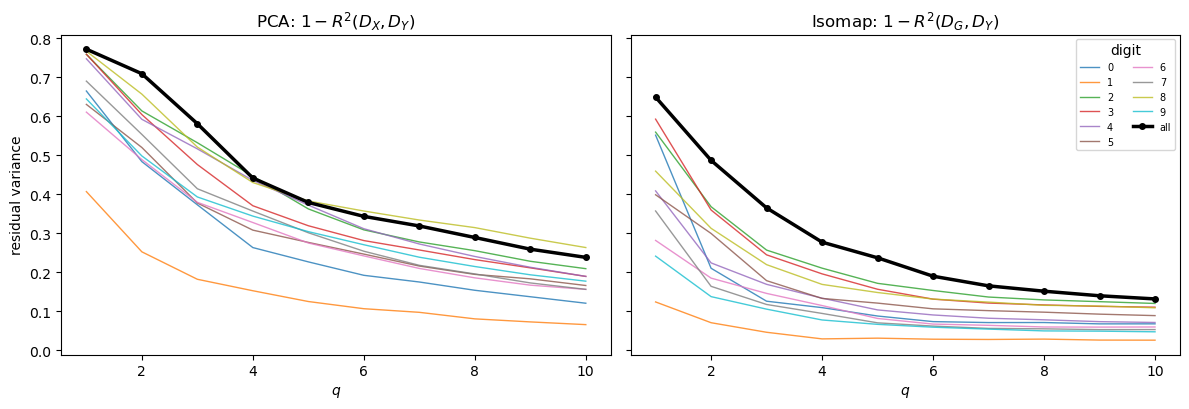

q              2             5             10       
           Isomap    PCA Isomap    PCA Isomap    PCA
all digits  0.487  0.709  0.237  0.379  0.132  0.238
digit 0     0.210  0.484  0.088  0.227  0.068  0.121
digit 1     0.071  0.252  0.031  0.125  0.026  0.066
digit 2     0.368  0.614  0.172  0.362  0.120  0.209
digit 3     0.360  0.604  0.156  0.319  0.111  0.189
digit 4     0.224  0.592  0.104  0.372  0.071  0.189
digit 5     0.299  0.520  0.121  0.277  0.089  0.166
digit 6     0.185  0.489  0.082  0.275  0.060  0.156
digit 7     0.164  0.553  0.070  0.301  0.053  0.156
digit 8     0.313  0.657  0.148  0.383  0.109  0.263
digit 9     0.138  0.498  0.067  0.304  0.047  0.177

In [16]:
def residual_variance(D_ref, Y, qs):
    d_ref = D_ref[np.triu_indices_from(D_ref, 1)]
    return [1 - np.corrcoef(d_ref, pdist(Y[:, :q]))[0, 1] ** 2 for q in qs]


QS = np.arange(1, 11)
K_RV = 10
rv = {}
samples = {"all digits": X[splits[0].tr]}
samples.update({f"digit {d}": X[data.class_subset(y, d, data.N_PER_SPLIT, seed=0)] for d in range(10)})
for label, Z in samples.items():
    e = fit_isomap(Z, QS.max(), n_neighbors=K_RV)
    rv[(label, "Isomap")] = residual_variance(e.info["model"].dist_matrix_, e.Y, QS)
    rv[(label, "PCA")] = residual_variance(cdist(Z, Z), fit_pca(Z, QS.max()).Y, QS)
rv = pd.DataFrame(rv, index=pd.Index(QS, name="q"))
rv.round(4).to_csv(RESULTS / "02_residual_variance.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, meth in zip(axes, ("PCA", "Isomap")):
    for d in range(10):
        ax.plot(QS, rv[(f"digit {d}", meth)], "-", c=COLORS(d), lw=1, alpha=0.8, label=f"{d}")
    ax.plot(QS, rv[("all digits", meth)], "k-o", lw=2.5, ms=4, label="all")
    ax.set(xlabel="$q$", title=f"{meth}" + (r": $1-R^2(D_G, D_Y)$" if meth == "Isomap" else r": $1-R^2(D_X, D_Y)$"))
axes[0].set_ylabel("residual variance")
axes[1].legend(title="digit", fontsize=7, ncol=2)
fig.tight_layout(); save(fig, "02_residual_variance"); plt.show()
rv.loc[[2, 5, 10]].T.unstack().round(3)

## 10. Conclusions

Numbers are mean ± s.d. over 5 splits, $n=2000$ (table below and `results/02_*_summary.csv`).

1. **Kernel PCA never beats PCA on MNIST.** The selected configurations sit at the PCA end of the grid ($c=10$, or a low-degree polynomial), and their scores equal PCA's to three decimals in both tracks ($\mathcal J\approx0.16$ at $q=2$, $\approx0.54$ at $q=10$). The $\sigma$-path (§7) shows why. For $c\gtrsim1$, kernel PCA *is* PCA (CCA similarity $>0.99$). For $c\lesssim0.3$, the quality falls to the random level. MNIST distances concentrate: the nearest neighbour lies at about half the median distance, so no bandwidth is local without also being blind to nearest neighbours. At $c=0.1$, $K\approx I$, the spectrum is flat ($d_{\mathrm{eff}}\to n$), and new points are mapped to $\approx0$ (the collapse predicted in `evaluation_protocol.tex`). Lesson: a median-scaled isotropic kernel does not help on high-dimensional data with concentrated distances.
2. **MDS = PCA**, as the theory says (checked in §2, identical scores everywhere), including the Gower out-of-sample map.
3. **Isomap wins in-sample, but most of the win does not transfer.**
   - Track B (in-sample): $\mathcal J=0.185$ vs $0.160$ ($q=2$, small $k$), $0.569$ vs $0.538$ ($q=10$, $k=100$). Isomap is also better on $T$, $C$, global Spearman and $k$-NN accuracy at $q=2$.
   - Track A (out-of-sample): at $q=2$ the gain survives ($0.186$ vs $0.160$, $k$-NN accuracy $0.48$ vs $0.41$). At $q=10$ it vanishes ($0.540$ vs $0.537$, and $k$-NN accuracy is slightly *lower*). Isomap has a generalisation gap of $0.03$; PCA's is $0.003$.
   - At $q=10$ the out-of-sample $R_{NX}$ curves show the trade: Isomap is better for large $K$ (global structure) but worse for $K\lesssim20$ (local neighbourhoods); at $q=2$ it is better at every $K$.
4. **$k$ is a bias–variance knob, and the best $k$ depends on $q$.** For $q=2$ a small graph ($k=5$–$10$) is best. For $q=10$ the score rises with $k$ up to a plateau at $k\approx100$–$500$, where Isomap moves towards PCA (CCA similarity $0.94\to0.97$). The grid's optimum $k=100$ is at its edge, but §8 shows the plateau, so extending the grid would not change the conclusion. The graph is connected for every $k\ge4$ at $n=2000$.
5. **MNIST geodesics are strongly non-Euclidean.** About 40% of the spectral mass of $B_G$ is negative for every $k$, against about 3% for a Swiss roll. It drops to $0$ only for the complete graph. So "all of MNIST" is not one flat manifold that Isomap could unroll isometrically. Classical MDS on $D_G$ must discard a large non-Euclidean part, which limits what any $q$-dimensional Isomap embedding can achieve.
6. **Single digits are much lower-dimensional than the whole dataset.** Isomap residual variance at $q=2$: digit 1 $0.07$, digits 7/9/6 $0.14$–$0.19$, versus $0.49$ for all digits. Per digit the elbow is at $q\approx2$–$4$, and Isomap beats PCA's residual variance at every $q$. This supports the picture from the per-class PCA in `01_baselines`: MNIST is a *union* of low-dimensional, curved class manifolds, and global spectral methods spend their few dimensions separating the classes rather than unrolling any one of them.

**For the group comparison:** PCA and Isomap ($q=2$: $k\approx10$; $q=10$: $k=100$) are the spectral entries worth carrying forward. Kernel PCA and MDS add nothing over PCA on MNIST, which is itself a result worth one slide. Open question for the talk: do local methods (LLE, LE, t-SNE, UMAP; notebooks 03–04) win at small $K$, where Isomap loses to PCA?

In [17]:
pd.concat({"Track B (in-sample, X_te)": summaryB[["J", "knn_acc", "selected"]],
           "Track A (out-of-sample)": summaryA[["J_oos", "gap", "knn_acc_oos", "selected"]]}, axis=1)

Track B (in-sample, X_te)                 \
                                  J        knn_acc   
q  method                                            
2  pca                 0.16 ± 0.002   0.412 ± 0.02   
10 pca                0.538 ± 0.001  0.862 ± 0.007   
2  mds                 0.16 ± 0.002   0.412 ± 0.02   
10 mds                0.538 ± 0.001  0.862 ± 0.007   
2  kpca                0.16 ± 0.002  0.406 ± 0.031   
10 kpca               0.538 ± 0.001  0.861 ± 0.006   
2  isomap             0.185 ± 0.007  0.469 ± 0.047   
10 isomap             0.569 ± 0.004  0.864 ± 0.008   

                                                             \
                                                   selected   
q  method                                                     
2  pca                                        -, -, -, -, -   
10 pca                                        -, -, -, -, -   
2  mds                                        -, -, -, -, -   
10 mds                                        -, -, -, -, -   
2  kpca    poly p=2, poly p=5, poly p=2, poly p=3, poly p=3   
10 kpca    rbf c=10, poly p=3, rbf c=10, rbf c=10, rbf c=10   
2  isomap                         k=20, k=5, k=5, k=10, k=5   
10 isomap                 k=100, k=100, k=100, k=100, k=100   

          Track A (out-of-sample)                                 \
                            J_oos             gap    knn_acc_oos   
q  method                                                          
2  pca               0.16 ± 0.005     0.0 ± 0.007  0.414 ± 0.008   
10 pca              0.537 ± 0.005   0.003 ± 0.002  0.862 ± 0.006   
2  mds               0.16 ± 0.005     0.0 ± 0.007  0.414 ± 0.008   
10 mds              0.537 ± 0.005   0.003 ± 0.002  0.862 ± 0.006   
2  kpca              0.16 ± 0.006   0.001 ± 0.007  0.411 ± 0.012   
10 kpca             0.537 ± 0.005   0.003 ± 0.002  0.862 ± 0.006   
2  isomap           0.186 ± 0.004  -0.001 ± 0.004  0.484 ± 0.021   
10 isomap            0.54 ± 0.004   0.028 ± 0.005  0.846 ± 0.014   

                                                             
                                                   selected  
q  method                                                    
2  pca                                        -, -, -, -, -  
10 pca                                        -, -, -, -, -  
2  mds                                        -, -, -, -, -  
10 mds                                        -, -, -, -, -  
2  kpca    rbf c=10, poly p=2, poly p=5, poly p=5, rbf c=10  
10 kpca    rbf c=10, rbf c=10, rbf c=10, rbf c=10, rbf c=10  
2  isomap                       k=10, k=10, k=10, k=10, k=5  
10 isomap                 k=100, k=100, k=100, k=100, k=100